# Baseline CNN from scratch, 224 px (R4)

This notebook trains a **small convolutional network from random weights** (no pre-trained weights) to classify the 200 bird species. It is the baseline for [`resnet50_altered_224px.ipynb`](resnet50_altered_224px.ipynb) and [`resnet50.ipynb`](resnet50.ipynb): it uses the **same photos, splits, augmentation, training loop, protocol and metrics**, so the only thing that differs is the network. The gap between the two shows how much ImageNet pre-training is worth on ~30 photos per species.

**Main metric:** macro-F1 on the official test split (accuracy and top-5 accuracy alongside), exactly as in the ResNet-50 notebooks. Results are written in the same file format (`*_results.json`, `*_history.csv`, `*_per_class_f1.csv`).

### Network (section 6)

| | |
|---|---|
| Blocks | 4 by default (`CHANNELS = (32, 64, 128, 256)`). Each block is 2 × [3×3 conv → batch norm → ReLU] then 2×2 max-pool, so 8 conv layers |
| Feature map | 224 → 112 → 56 → 28 → 14 px |
| Head | global average pool → dropout 0.3 → linear 256 → 200 |
| Size | about 1.2 million weights (ResNet-50 has 23.9 million) |

Change `CHANNELS` in section 1 to try 3 blocks `(32, 64, 128)` or 5 blocks `(32, 64, 128, 256, 512)`; the run names include the number of blocks, so the results do not overwrite each other.

### Data pipeline (unchanged from the ResNet-50 notebooks)
Photos cropped to the bounding box + 10% margin by `scripts/prepare_images.py` (shorter side 256 px), checked by `05_image_preparation.ipynb`, split and augmented by `scripts/augmentation.py` (`make_splits`, `train_transform`, `eval_transform`, `BirdImages`), imported unchanged. The report should say that the photos are cropped with the dataset's bounding boxes on train **and** test.

### Protocol (no test leakage)
1. **Select** (section 7): for each learning rate, train on the 80% training part and score the validation part after every epoch. The rate with the best validation macro-F1 wins.
2. **Final** (section 8): retrain from random weights on all 5,994 training photos with that rate, for the same number of epochs, and keep the last epoch.
3. **Test** (section 9): the official test photos are scored **once**, at the end.

### How to run
- **Colab (recommended):** File → Open notebook → GitHub → `Flamingsides/f20dl-coursework-1`, branch `david-base-cnn` (push the branch first). Runtime → Change runtime type → **T4 or L4 GPU**. The first time only, put your `kaggle.json` in Google Drive at `MyDrive/f20dl_base_cnn/kaggle.json`. Then Runtime → Run all. If Colab disconnects, run all again: every run resumes from its last saved epoch.
- **Locally (VS Code):** set `SMOKE_TEST = True` first to check the code runs end to end. A full run on a CPU takes many hours, so do the real runs on a GPU.

*Code adapted from `resnet50_altered_224px.ipynb` with help from Claude (Anthropic).*

## 1. Settings

In [1]:
SMOKE_TEST = False     # True = tiny subset, 1 epoch: only checks that the code runs end to end

REPO_URL = "https://github.com/Flamingsides/f20dl-coursework-1.git"
BRANCH = "base-cnn"         # the branch Colab clones; change to "main" once this is merged
DRIVE_FOLDER = "f20dl_base_cnn"   # folder in MyDrive for the data cache, checkpoints and results

# Network: one entry per conv block (number of filters). 4 blocks = 224 -> 14 px feature map.
CHANNELS = (32, 64, 128, 256)
DROPOUT = 0.3

BATCH_SIZE = 64
EPOCHS = 60                  # from random weights the network needs far more epochs than fine-tuning (25)
# Learning rates to try. 0.025 is the standard from-scratch rate (0.1 x batch / 256, as in resnet50.ipynb's
# PRETRAINED = False settings); try it, a third of it and 3x it.
LR_GRID = [0.01, 0.025, 0.075]
WARMUP_EPOCHS, WEIGHT_DECAY = 3, 5e-4   # more regularisation than fine-tuning: ~24 photos per species, no prior
HEAD_LR_MULT = 1             # nothing is pre-trained, so every layer uses the same learning rate
LABEL_SMOOTHING = 0.1

if SMOKE_TEST:
    EPOCHS, WARMUP_EPOCHS, BATCH_SIZE, LR_GRID = 1, 0, 8, LR_GRID[:2]

BASE_NAME = f"base_cnn_{len(CHANNELS)}blocks_224px" + ("_smoke" if SMOKE_TEST else "")
CONFIG = dict(pipeline="05_image_preparation", weights=None, channels=list(CHANNELS), dropout=DROPOUT,
              img_size=224, store_px=256, batch_size=BATCH_SIZE, epochs=EPOCHS, warmup_epochs=WARMUP_EPOCHS,
              head_lr_mult=HEAD_LR_MULT, weight_decay=WEIGHT_DECAY, label_smoothing=LABEL_SMOOTHING,
              smoke_test=SMOKE_TEST)
print(f"{BASE_NAME}: learning rates {LR_GRID}")
CONFIG

base_cnn_4blocks_224px: learning rates [0.01, 0.025, 0.075]


{'pipeline': '05_image_preparation',
 'weights': None,
 'channels': [32, 64, 128, 256],
 'dropout': 0.3,
 'img_size': 224,
 'store_px': 256,
 'batch_size': 64,
 'epochs': 60,
 'warmup_epochs': 3,
 'head_lr_mult': 1,
 'weight_decay': 0.0005,
 'label_smoothing': 0.1,
 'smoke_test': False}

## 2. Environment

On Colab: mount Google Drive and clone the repository (for the pipeline notebooks and scripts). Locally: use this repository.

In [2]:
import json
import math
import os
import shutil
import subprocess
import sys
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from IPython.display import Image as ShowImage, display

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive") / DRIVE_FOLDER
    DRIVE.mkdir(parents=True, exist_ok=True)
    ROOT = Path("/content/f20dl-coursework-1")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(ROOT)], check=True)
    OUT = DRIVE                                    # survives disconnects
    CKPT_DIR = DRIVE / "checkpoints"
else:
    DRIVE = None
    ROOT = Path.cwd() if (Path.cwd() / "notebooks").exists() else Path.cwd().parent
    OUT = ROOT / "results" / "base_cnn"
    CKPT_DIR = ROOT / "data" / "processed" / "checkpoints"   # git-ignored: checkpoints are ~15 MB each

FIGURES = OUT / "figures"
for d in (OUT, CKPT_DIR, FIGURES):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts"))

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    torch.backends.cudnn.benchmark = True          # picks the fastest convolution algorithms for fixed-size inputs
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"                    # mixed precision: ~2x faster, same accuracy
GPU = torch.cuda.get_device_name() if DEVICE.type == "cuda" else ""

print(f"Colab: {IN_COLAB} | device: {DEVICE} {GPU} | {os.cpu_count()} CPU cores")
print(f"torch {torch.__version__} | outputs -> {OUT}")
if IN_COLAB and DEVICE.type != "cuda":
    raise RuntimeError("No GPU: Runtime -> Change runtime type -> T4 or L4 GPU, then run all again.")

Colab: False | device: cuda NVIDIA GeForce RTX 3060 Laptop GPU | 16 CPU cores
torch 2.11.0+cu128 | outputs -> c:\Projects\F20DL\f20dl-coursework-1\results\base_cnn


## 3. Build the cropped photos (imagePrep → prepare_images.py)

1. **Original photos**: downloaded from Kaggle with `scripts/download_data.py` if missing.
2. **Cropped photos**: restored from the Drive cache if it exists; otherwise `imagePrep.ipynb` checks every photo and `scripts/prepare_images.py` (default settings: 256 px) crops them, and the result is cached in Drive.

Colab does not show the output of these helper programs while they run, so this cell can look idle for a few minutes (up to ~10 the first time).

In [3]:
DATA = ROOT / "data"
PROCESSED = DATA / "processed"
CSV = PROCESSED / "cub_images_cropped.csv"         # the file 05_image_preparation.ipynb checks
IMG_DIR = PROCESSED / "images_cropped"
CACHE_ZIP = DRIVE / "cub_processed_256px.zip" if IN_COLAB else None   # same cache name as the ResNet notebooks

def run(cmd):
    print("$", " ".join(map(str, cmd)), flush=True)
    subprocess.run(list(map(str, cmd)), check=True, cwd=ROOT)

# 1. Original photos (imagePrep needs them, and so does the before / after figure in 05)
if not (any((DATA / "raw").rglob("image_class_labels.txt")) or (ROOT / "CUB_200_2011").exists()):
    if IN_COLAB:
        token = DRIVE / "kaggle.json"
        if not token.exists():
            raise FileNotFoundError(f"Put your kaggle.json in Google Drive at {token} (see the top of this notebook)")
        kaggle_dir = Path.home() / ".kaggle"
        kaggle_dir.mkdir(exist_ok=True)
        shutil.copy(token, kaggle_dir / "kaggle.json")
        os.chmod(kaggle_dir / "kaggle.json", 0o600)
    run([sys.executable, "scripts/download_data.py"])

# 2. Cropped photos
if not CSV.exists() and IN_COLAB and CACHE_ZIP.exists():
    print("Restoring the cropped photos from the Drive cache...", flush=True)
    shutil.unpack_archive(CACHE_ZIP, DATA)
if not CSV.exists():
    if not (DATA / "cub_images.csv").exists():
        run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute", "--output-dir", PROCESSED / "_executed",
             "notebooks/imagePrep.ipynb"])
    run([sys.executable, "scripts/prepare_images.py"])
    if IN_COLAB:
        print("Caching the cropped photos in Drive...", flush=True)
        local_zip = Path("/content") / CACHE_ZIP.name     # build locally, then one copy to Drive (much faster)
        with zipfile.ZipFile(local_zip, "w", zipfile.ZIP_STORED) as z:   # JPEGs are already compressed
            z.write(CSV, CSV.relative_to(DATA))
            for p in IMG_DIR.rglob("*"):
                if p.is_file():
                    z.write(p, p.relative_to(DATA))
        shutil.copy(local_zip, CACHE_ZIP)

print(f"{CSV.relative_to(ROOT)}: {len(pd.read_csv(CSV)):,} photos")

data\processed\cub_images_cropped.csv: 11,788 photos


## 4. Run `05_image_preparation.ipynb`

The pipeline notebook is executed as it is in the repository. Its checks stop this notebook with an error if anything is wrong:
- all 11,788 photos were cropped, are RGB and have a 256 px shorter side;
- train, validation and test share no photo, validation comes from the official training split, and all 200 species are in train and validation.

Its executed copy is saved next to the results, and its two figures are shown below.

$ d:\Anaconda\envs\f20dl-birds\python.exe -m jupyter nbconvert --to notebook --execute --output-dir c:\Projects\F20DL\f20dl-coursework-1\data\processed\_executed notebooks/05_image_preparation.ipynb
OK: 11,788 cropped RGB images, shorter side 256 px
train 4,795 | val 1,199 | test 5,794
OK: no overlap, val comes from the official train split, all 200 species in train and val


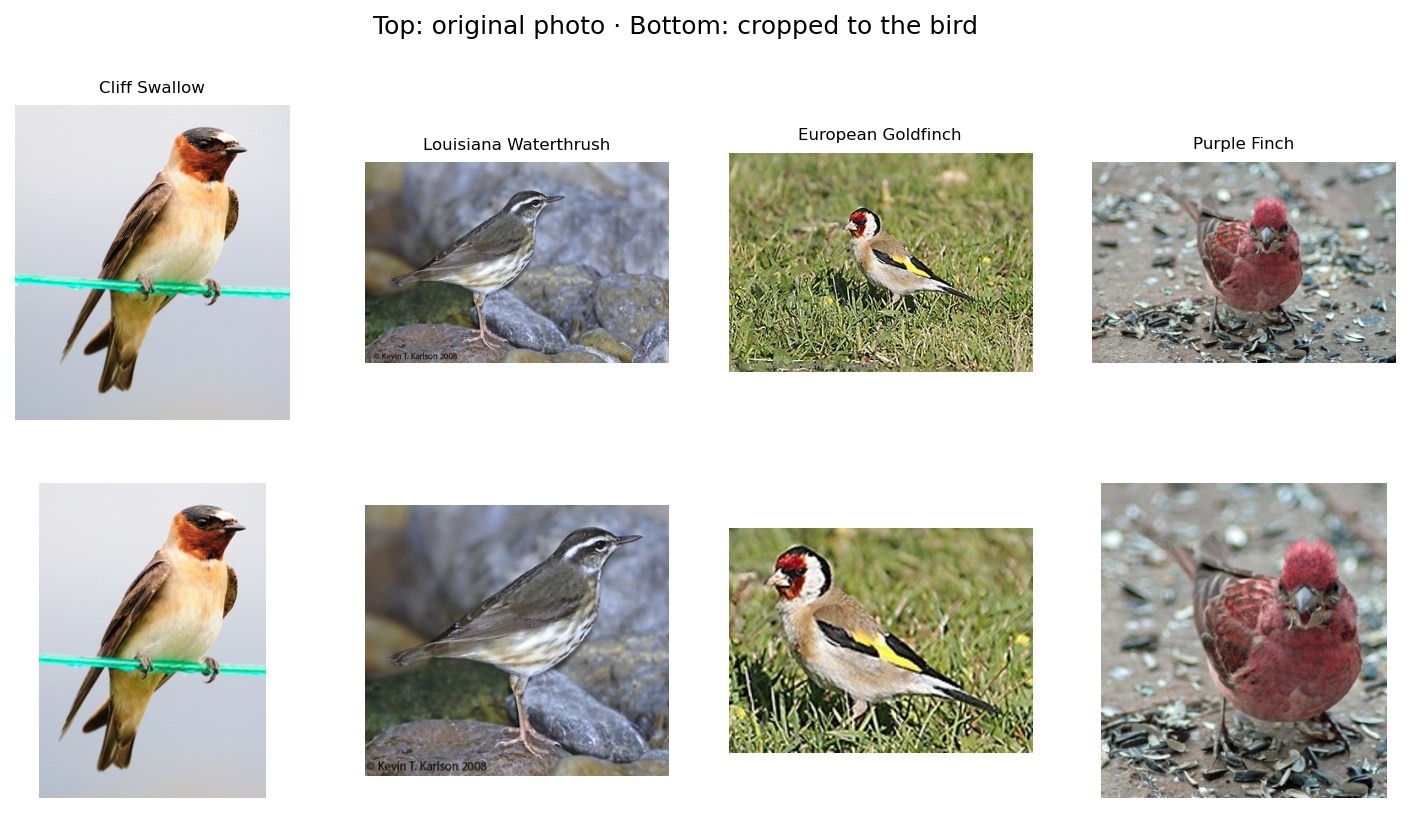

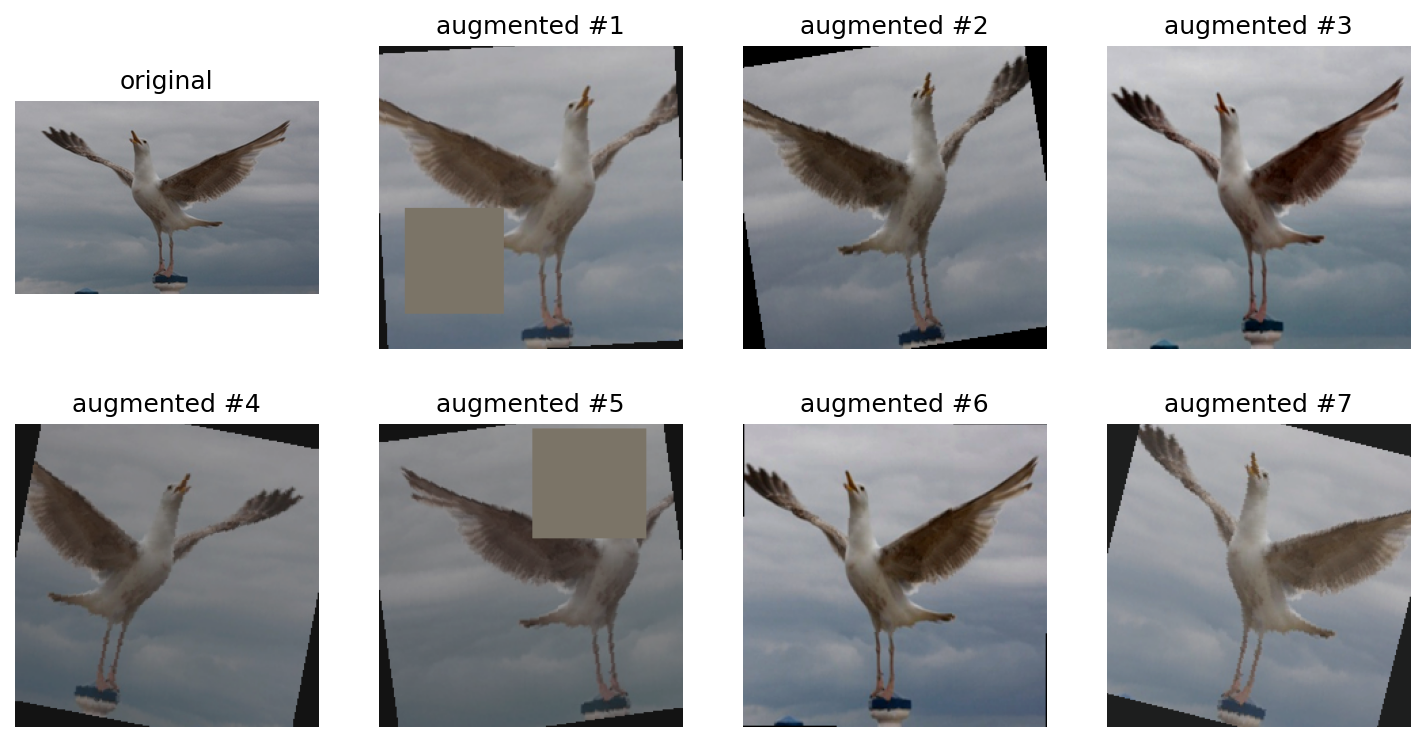

In [4]:
EXECUTED = PROCESSED / "_executed"
run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute", "--output-dir", EXECUTED,
     "notebooks/05_image_preparation.ipynb"])

executed = json.loads((EXECUTED / "05_image_preparation.ipynb").read_text())
for cell in executed["cells"]:
    for out in cell.get("outputs", []):
        if out.get("name") == "stdout":
            print("".join(out["text"]).strip())
if IN_COLAB:
    shutil.copy(EXECUTED / "05_image_preparation.ipynb", OUT / "05_image_preparation_executed.ipynb")
for name in ("05_crop_examples", "05_augmentation_examples"):
    display(ShowImage(filename=str(ROOT / "documentation" / "figures" / f"{name}.png"), width=800))

## 5. Splits, transforms and loaders from `scripts/augmentation.py`

The same `make_splits`, `train_transform`, `eval_transform` and `BirdImages` that `05` checks and shows, imported unchanged. Only the loader settings (batch size, worker processes) are chosen here, for speed on the GPU.

In [5]:
from augmentation import (BirdImages, make_splits, train_transform, eval_transform,
                          IMG_SIZE, N_CLASSES, RANDOM_STATE)

assert IMG_SIZE == CONFIG["img_size"]
train_df, val_df, test_df = make_splits(CSV)
if SMOKE_TEST:   # 10 species, a few photos each
    pick = lambda df, n: df[df.class_id <= 10].groupby("class_id").head(n)
    train_df, val_df, test_df = pick(train_df, 4), pick(val_df, 2), pick(test_df, 3)
full_train_df = pd.concat([train_df, val_df])     # all official training photos, for the final retrain
assert not set(full_train_df.image_id) & set(test_df.image_id)
assert not set(train_df.image_id) & set(val_df.image_id)

NUM_WORKERS = 0 if SMOKE_TEST else min(12, os.cpu_count() or 2)

def make_loader(df, train):
    return DataLoader(BirdImages(df, PROCESSED, train_transform if train else eval_transform),
                      batch_size=BATCH_SIZE, shuffle=train, drop_last=train, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0,
                      generator=torch.Generator().manual_seed(RANDOM_STATE) if train else None)

species = (pd.read_csv(CSV)[["class_id", "species"]].drop_duplicates()
           .set_index("class_id").sort_index().species.tolist())       # index = class_id - 1
print(f"train {len(train_df):,} | val {len(val_df):,} | all training {len(full_train_df):,} | "
      f"test {len(test_df):,} photos | input {IMG_SIZE} px | {NUM_WORKERS} loader workers")

train 4,795 | val 1,199 | all training 5,994 | test 5,794 photos | input 224 px | 12 loader workers


## 6. Model and training code

- **Baseline CNN** (`BaseCNN` below), built from random weights. Each block is two 3×3 convolutions with batch norm and ReLU, then a 2×2 max-pool that halves the feature map and doubles the number of filters (the VGG pattern). Two stacked 3×3 convolutions see a 5×5 patch with fewer weights than one 5×5 convolution.
- **Global average pooling** instead of flattening the 14×14×256 map: the head has 51 k weights instead of 10 million, which matters with ~24 training photos per species.
- **Dropout 0.3** before the classifier, **weight decay 5e-4** and **label smoothing 0.1** against memorising the training photos.
- The **optimiser, schedule, mixed precision, checkpoints and metrics are the ones in the ResNet-50 notebooks**: SGD with momentum 0.9, warm-up then cosine decay, scored with accuracy, macro-F1 and top-5 accuracy. With `HEAD_LR_MULT = 1` the two learning-rate groups are equal, so `lr_backbone` in the results is simply the learning rate.

In [6]:
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP)

def conv_block(c_in, c_out):
    """2 x (3x3 conv -> batch norm -> ReLU), then 2x2 max-pool (halves height and width)."""
    layers = []
    for c in (c_in, c_out):
        layers += [nn.Conv2d(c, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]
    return nn.Sequential(*layers, nn.MaxPool2d(2))


class BaseCNN(nn.Module):
    def __init__(self, channels=CHANNELS, n_classes=N_CLASSES, dropout=DROPOUT):
        super().__init__()
        ins = (3, *channels[:-1])
        self.features = nn.Sequential(*[conv_block(i, o) for i, o in zip(ins, channels)])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[-1], n_classes)   # named fc like ResNet's classifier, so new_optimiser works unchanged
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.fc(self.dropout(self.pool(self.features(x)).flatten(1)))


def new_model():
    torch.manual_seed(RANDOM_STATE)
    model = BaseCNN()
    return model.to(DEVICE, memory_format=torch.channels_last)


_m = BaseCNN()
print(f"BaseCNN: {len(CHANNELS)} blocks, {2 * len(CHANNELS)} conv layers, "
      f"{sum(p.numel() for p in _m.parameters()):,} weights, "
      f"feature map {224 // 2 ** len(CHANNELS)}x{224 // 2 ** len(CHANNELS)} before pooling")
del _m

def new_optimiser(model, lr_backbone, steps_per_epoch):
    head = list(model.fc.parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.SGD([{"params": backbone, "lr": lr_backbone},
                                 {"params": head, "lr": lr_backbone * HEAD_LR_MULT}],
                                momentum=0.9, nesterov=True, weight_decay=WEIGHT_DECAY)
    steps, warmup = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
    def lr_factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, steps - warmup)))
    return optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

def train_one_epoch(model, loader, optimizer, scheduler, scaler):
    model.train()
    loss_sum, correct, seen = 0.0, 0, 0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with autocast():
            logits = model(x)
            loss = criterion(logits, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        loss_sum += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        seen += len(y)
    return loss_sum / seen, correct / seen

@torch.no_grad()
def predict(model, loader):
    """Class probabilities, true labels (0-199) and mean cross-entropy (without smoothing)."""
    model.eval()
    probs, labels, loss_sum = [], [], 0.0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with autocast():
            logits = model(x)
        loss_sum += nn.functional.cross_entropy(logits.float(), y, reduction="sum").item()
        probs.append(logits.float().softmax(1).cpu())
        labels.append(y.cpu())
    probs, labels = torch.cat(probs).numpy(), torch.cat(labels).numpy()
    return probs, labels, loss_sum / len(labels)

def scores(probs, labels):
    preds = probs.argmax(1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro"),
            "top5_accuracy": top_k_accuracy_score(labels, probs, k=5, labels=np.arange(N_CLASSES))}

def save_atomic(obj, path):
    tmp = path.with_suffix(".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def fit(run_name, train_rows, val_rows, lr_backbone):
    """Train one run (resumable). With validation rows, keep the epoch with the best validation macro-F1;
    without, keep the last epoch. Returns the epoch history and a summary; the kept weights are in <run>_best.pt."""
    config = {**CONFIG, "run": run_name, "lr_backbone": lr_backbone, "train_photos": len(train_rows)}
    last, best_path = CKPT_DIR / f"{run_name}_last.pt", CKPT_DIR / f"{run_name}_best.pt"
    train_loader = make_loader(train_rows, train=True)
    val_loader = make_loader(val_rows, train=False) if val_rows is not None else None
    model = new_model()
    optimizer, scheduler = new_optimiser(model, lr_backbone, len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    start, history, best = 0, [], {"epoch": 0, "val": None}
    if last.exists():
        ckpt = torch.load(last, map_location=DEVICE, weights_only=False)
        if ckpt["config"] != config:
            raise ValueError(f"{last.name} was saved with different settings - delete it to start this run again")
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        scaler.load_state_dict(ckpt["scaler"])
        start, history, best = ckpt["epoch"] + 1, ckpt["history"], ckpt["best"]
        print(f"{run_name}: resuming after epoch {start}" if start < EPOCHS else f"{run_name}: already finished")

    for epoch in range(start, EPOCHS):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scheduler, scaler)
        row = {"epoch": epoch + 1, "train_loss": train_loss, "train_accuracy": train_acc}
        if val_loader is not None:
            val_probs, val_labels, val_loss = predict(model, val_loader)
            val = scores(val_probs, val_labels)
            row.update(val_loss=val_loss, **{f"val_{k}": v for k, v in val.items()})
        row["seconds"] = time.time() - t0
        history.append(row)
        keep = val_loader is None or best["val"] is None or val["macro_f1"] > best["val"]["macro_f1"]
        if keep:
            best = {"epoch": epoch + 1, "val": val if val_loader is not None else None}
            save_atomic({"model": model.state_dict(), "config": config, **best}, best_path)
        save_atomic({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                     "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                     "history": history, "best": best, "config": config}, last)
        msg = f"{run_name} | epoch {epoch + 1:>2}/{EPOCHS} | train loss {train_loss:.3f} acc {train_acc:.3f}"
        if val_loader is not None:
            msg += (f" | val loss {val_loss:.3f} acc {val['accuracy']:.3f} macro-F1 {val['macro_f1']:.3f}"
                    f" top-5 {val['top5_accuracy']:.3f}")
        print(msg + f" | {row['seconds']:.0f}s" + ("  *" if keep and val_loader is not None else ""), flush=True)

    history = pd.DataFrame(history)
    history.to_csv(OUT / f"{run_name}_history.csv", index=False)
    del model, optimizer, scheduler
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return history, {"run": run_name, "lr_backbone": lr_backbone, "best_epoch": best["epoch"], "val": best["val"],
                     "train_minutes": round(history.seconds.sum() / 60, 1)}

BaseCNN: 4 blocks, 8 conv layers, 1,224,616 weights, feature map 14x14 before pooling


## 7. Select the learning rate (train on 80%, score on validation)

One run per backbone learning rate in `LR_GRID`, each scored on the validation photos after every epoch.

In [ ]:
selection = {lr: fit(f"{BASE_NAME}_lr{lr:g}", train_df, val_df, lr) for lr in LR_GRID}

selection_table = pd.DataFrame([{"backbone lr": lr, "run": s["run"], "best epoch": s["best_epoch"],
                                 "val accuracy": s["val"]["accuracy"], "val macro-F1": s["val"]["macro_f1"],
                                 "val top-5": s["val"]["top5_accuracy"], "minutes": s["train_minutes"]}
                                for lr, (_, s) in selection.items()])
BEST_LR = max(selection, key=lambda lr: selection[lr][1]["val"]["macro_f1"])
print(f"Chosen backbone learning rate: {BEST_LR:g}")
if BEST_LR in (min(LR_GRID), max(LR_GRID)) and len(LR_GRID) > 1:
    print("Note: the best rate is at the edge of LR_GRID, so a rate outside the grid might do better.")
selection_table.round(4)

base_cnn_4blocks_224px_lr0.01 | epoch  1/60 | train loss 5.411 acc 0.006 | val loss 5.255 acc 0.008 macro-F1 0.001 top-5 0.036 | 236s  *
base_cnn_4blocks_224px_lr0.01 | epoch  2/60 | train loss 5.271 acc 0.012 | val loss 5.094 acc 0.026 macro-F1 0.009 top-5 0.095 | 75s  *
base_cnn_4blocks_224px_lr0.01 | epoch  3/60 | train loss 5.137 acc 0.019 | val loss 4.899 acc 0.027 macro-F1 0.009 top-5 0.119 | 76s
base_cnn_4blocks_224px_lr0.01 | epoch  4/60 | train loss 5.008 acc 0.023 | val loss 4.770 acc 0.038 macro-F1 0.011 top-5 0.143 | 75s  *
base_cnn_4blocks_224px_lr0.01 | epoch  5/60 | train loss 4.906 acc 0.030 | val loss 4.704 acc 0.045 macro-F1 0.024 top-5 0.168 | 75s  *
base_cnn_4blocks_224px_lr0.01 | epoch  6/60 | train loss 4.831 acc 0.036 | val loss 4.626 acc 0.050 macro-F1 0.029 top-5 0.191 | 76s  *
base_cnn_4blocks_224px_lr0.01 | epoch  7/60 | train loss 4.788 acc 0.042 | val loss 4.607 acc 0.053 macro-F1 0.028 top-5 0.170 | 77s
base_cnn_4blocks_224px_lr0.01 | epoch  8/60 | train l

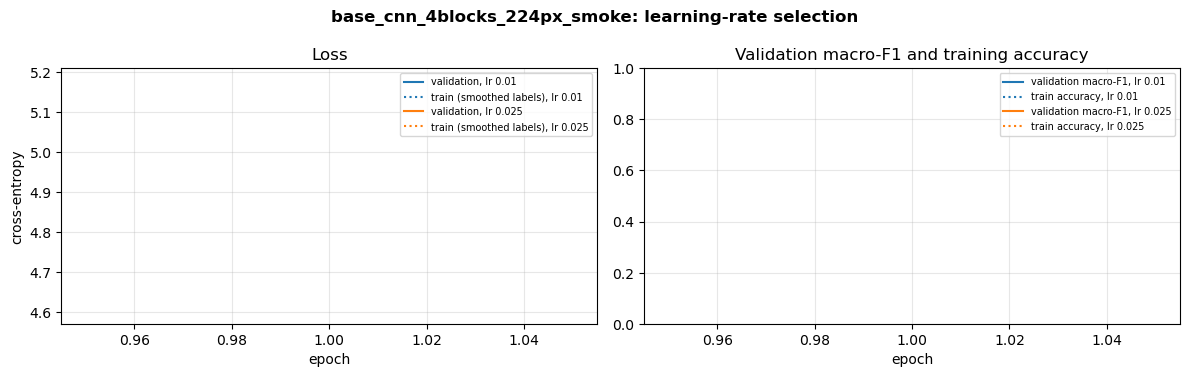

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for lr, (hist, s) in selection.items():
    line, = axes[0].plot(hist.epoch, hist.val_loss, label=f"validation, lr {lr:g}")
    axes[0].plot(hist.epoch, hist.train_loss, ":", color=line.get_color(), label=f"train (smoothed labels), lr {lr:g}")
    line, = axes[1].plot(hist.epoch, hist.val_macro_f1, label=f"validation macro-F1, lr {lr:g}")
    axes[1].plot(hist.epoch, hist.train_accuracy, ":", color=line.get_color(), label=f"train accuracy, lr {lr:g}")
axes[0].set(title="Loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].set(title="Validation macro-F1 and training accuracy", xlabel="epoch", ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.suptitle(f"{BASE_NAME}: learning-rate selection", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES / f"{BASE_NAME}_curves.png", dpi=150, bbox_inches="tight")
plt.show()

A widening gap between training accuracy and validation macro-F1 means the network is memorising the training photos (overfitting). Validation macro-F1 levelling off shows where more epochs stop helping.

## 8. Final model (retrain on all training photos)

Once the learning rate is chosen the validation photos are not needed any more, so the final model is trained again from random weights on all 5,994 training photos (~25% more photos per species), and the last epoch is kept.

In [ ]:
FINAL_NAME = f"{BASE_NAME}_final"
final_history, final_summary = fit(FINAL_NAME, full_train_df, None, BEST_LR)
print(f"Final model: {FINAL_NAME} ({final_summary['train_minutes']} min)")

base_cnn_4blocks_224px_smoke_final | epoch  1/1 | train loss 4.534 acc 0.036 | 1s
Final model: base_cnn_4blocks_224px_smoke_final (0.0 min)


## 9. Final test evaluation (run once)

The final model is scored once on the 5,794 official test photos, then compared with the attribute-based models and every ResNet-50 and baseline CNN run whose results file is in `results/`.

In [ ]:
model = new_model()
final_ckpt = torch.load(CKPT_DIR / f"{FINAL_NAME}_best.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(final_ckpt["model"])
test_probs, test_labels, test_loss = predict(model, make_loader(test_df, train=False))
test = scores(test_probs, test_labels)

results = {"run": FINAL_NAME, "config": {**CONFIG, "lr_backbone": BEST_LR, "final_retrain": True},
           "selection": selection_table.to_dict("records"), "final_epoch": final_ckpt["epoch"],
           "test": test, "test_photos": int(len(test_labels)),
           "train_minutes_total": round(sum(s["train_minutes"] for _, s in selection.values())
                                        + final_summary["train_minutes"], 1)}
(OUT / f"{FINAL_NAME}_results.json").write_text(json.dumps(results, indent=2))

per_class = pd.DataFrame({"class_id": np.arange(1, N_CLASSES + 1), "species": species,
                          "f1": f1_score(test_labels, test_probs.argmax(1), average=None, labels=np.arange(N_CLASSES))})
per_class.to_csv(OUT / f"{FINAL_NAME}_per_class_f1.csv", index=False)
print(f"{FINAL_NAME} | test accuracy {test['accuracy']:.4f} | macro-F1 {test['macro_f1']:.4f} | "
      f"top-5 {test['top5_accuracy']:.4f}")

# Best attribute-based results on the same official test split (from the notebooks named), plus every ResNet-50
# run in results/resnet50/ (committed by Ryan) and every baseline CNN run in the output folder
rows = [("Random forest, tuned (randomForest.ipynb)", "312 attributes", 0.4563, 0.4349, 0.7206),
        ("RF + logistic regression ensemble (randomForestOptimisation.ipynb)", "attributes + aggregates",
         0.5104, 0.5059, 0.7656)]
for path in sorted(ROOT.glob("results/resnet50/resnet50_*_results.json")) + sorted(OUT.glob("base_cnn_*_results.json")):
    r = json.loads(path.read_text())
    rows.append((r["run"], "photos", r["test"]["accuracy"], r["test"]["macro_f1"], r["test"]["top5_accuracy"]))
pd.DataFrame(rows, columns=["model", "input", "test accuracy", "test macro-F1", "test top-5"]).round(4)

base_cnn_4blocks_224px_smoke_final | test accuracy 0.1000 | macro-F1 0.0182 | top-5 0.5667


d:\Anaconda\envs\f20dl-birds\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,model,input,test accuracy,test macro-F1,test top-5
0,"Random forest, tuned (randomForest.ipynb)",312 attributes,0.4563,0.4349,0.7206
1,RF + logistic regression ensemble (randomFores...,attributes + aggregates,0.5104,0.5059,0.7656
2,resnet50_altered_224px_final,photos,0.8032,0.8011,0.9417
3,resnet50_pretrained_224px,photos,0.7637,0.7640,0.9351
4,resnet50_pretrained_448px_final,photos,0.8188,0.8179,0.9496
5,base_cnn_4blocks_224px_smoke_final,photos,0.1000,0.0182,0.5667


## 10. Which species does it confuse?

The most frequent test mistakes, as (true species → predicted species).

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_labels, test_probs.argmax(1), labels=np.arange(N_CLASSES))
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm, axis=None)[::-1][:10], cm.shape))[0]
print(pd.DataFrame([(species[t], species[p], cm[t, p], int((test_labels == t).sum())) for t, p in top],
                   columns=["true species", "predicted as", "mistakes", "test photos of true species"]).to_string())

             true species          predicted as  mistakes  test photos of true species
0       Rhinoceros Auklet        Crested Auklet         3                            3
1       Groove billed Ani        Crested Auklet         3                            3
2    Red winged Blackbird        Crested Auklet         3                            3
3  Black footed Albatross        Crested Auklet         3                            3
4        Laysan Albatross        Crested Auklet         3                            3
5        Brewer Blackbird        Crested Auklet         3                            3
6         Sooty Albatross        Crested Auklet         3                            3
7            Least Auklet        Crested Auklet         3                            3
8         Parakeet Auklet        Crested Auklet         3                            3
9        Anna Hummingbird  Cape Glossy Starling         0                            0


## 11. Files written

All in `MyDrive/f20dl_base_cnn/` on Colab (`results/base_cnn/` locally).
- `base_cnn_4blocks_224px_final_results.json`: settings, learning-rate selection, test scores
- `base_cnn_4blocks_224px_*_history.csv`: one row per epoch for every run
- `base_cnn_4blocks_224px_final_per_class_f1.csv`: test F1 for each species
- `figures/base_cnn_4blocks_224px_curves.png`: learning curves
- `05_image_preparation_executed.ipynb` (Colab only): the executed pipeline notebook with its checks

The `checkpoints/` folder and the `cub_processed_*.zip` cache are large and only needed on Colab: they are not committed. 